In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import missingno as msno
import data_profiling

/tmp/ipykernel_1889/2879000656.py:7: DeprecationWarning:
    `import ydata_profiling` is deprecated and will not receive more updates.
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.

  from ydata_profiling import ProfileReport

In [ ]:
df = pd.read_csv("/content/dataset.csv", encoding="utf-8")

Calculate the missing count with pct and duplicated rows

In [ ]:
df.isna().sum()
missing_summary = pd.DataFrame(
    {"missing_count": df.isna().sum(), "missing_pct": df.isna().mean() * 100}
)

missing_summary = missing_summary[missing_summary["missing_count"] > 0].sort_values(
    "missing_pct", ascending=False
)
missing_summary

duplicate_rows = df.duplicated().sum()
print(f"Duplicated rows: {duplicate_rows}")

np.int64(0)

In [5]:
df.shape
df.dtypes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CUST_ID                 8950 non-null   object 
 1   BALANCE                 8950 non-null   float64
 2   PURCHASES               8950 non-null   float64
 3   ONEOFF_PURCHASES        8950 non-null   float64
 4   INSTALLMENTS_PURCHASES  8950 non-null   float64
 5   CASH_ADVANCE            8950 non-null   float64
 6   CREDIT_LIMIT            8949 non-null   float64
 7   PAYMENTS                8950 non-null   float64
dtypes: float64(7), object(1)
memory usage: 559.5+ KB


In [ ]:
df.describe(include="all")

In [ ]:
# histogramme, boxplot, barplot

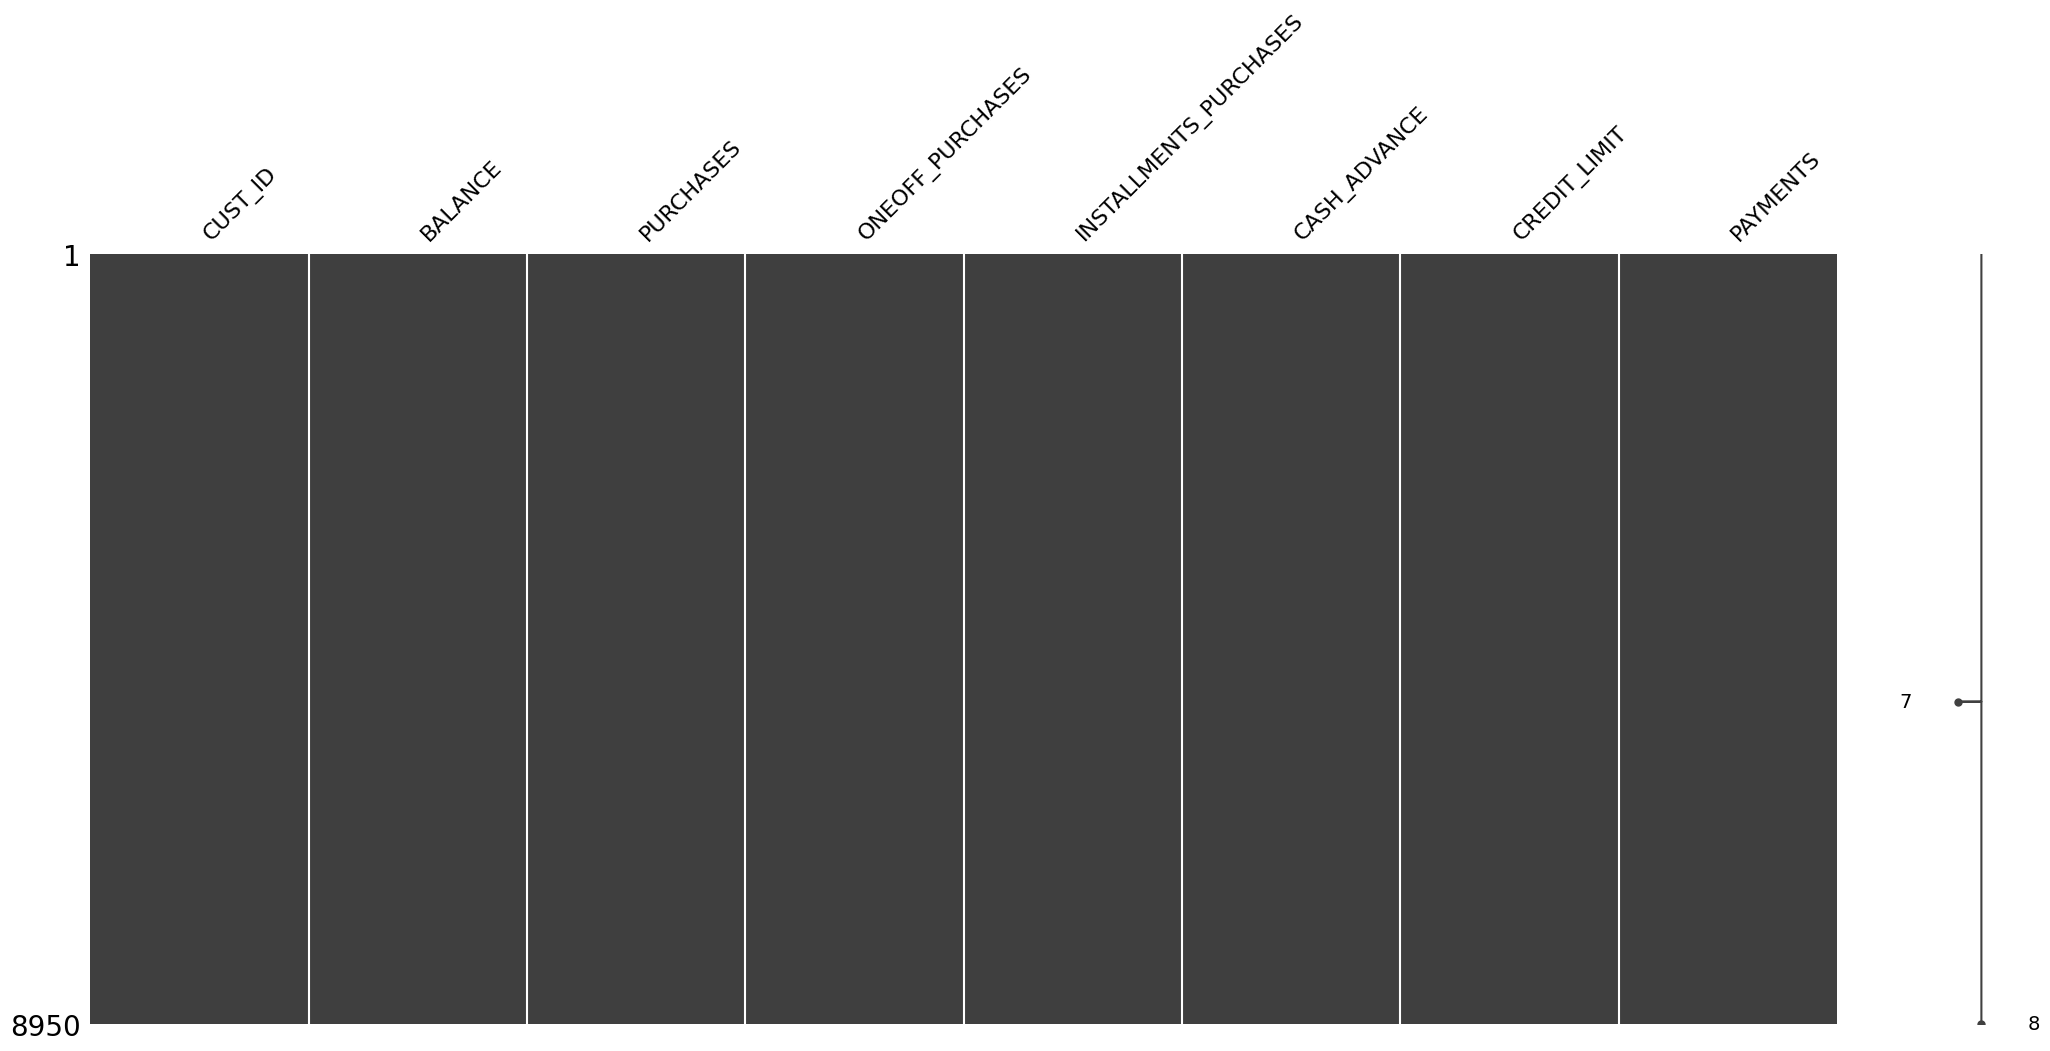

In [8]:
msno.matrix(df)
plt.show()

In [9]:
df.columns

Index(['CUST_ID', 'BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES',
       'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS'],
      dtype='object')

In [ ]:
NUMERIC_COLUMNS = [
    "BALANCE",
    "PURCHASES",
    "ONEOFF_PURCHASES",
    "INSTALLMENTS_PURCHASES",
    "CASH_ADVANCE",
    "CREDIT_LIMIT",
    "PAYMENTS",
]

n_cols = len(NUMERIC_COLUMNS)
fig, axes = plt.subplots(n_cols, 2, figsize=(14, 3 * n_cols))

for i, col in enumerate(NUMERIC_COLUMNS):
    skwe = df[col].skew()
    sns.histplot(df[col], bins=30, ax=axes[i, 0], kde=True)
    axes[i, 0].set_title(f"Histogram of {col}, skwe={skwe:.2f}")
    sns.boxplot(x=df[col], ax=axes[i, 1])
    axes[i, 1].set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

In [ ]:
corr = df.select_dtypes(include=np.number).corr()
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

In [12]:
profile = data_profiling.ProfileReport(df, title="EDA Report")
profile.to_file("eda_report.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 8/8 [00:00<00:00, 45.90it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
outliers = []
for col in NUMERIC_COLUMNS:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    mask = (df[col] < lower_bound) | (df[col] > upper_bound)
    outliers.append(
        {
            "column": col,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "outlier_count": mask.sum(),
            "outlier_pct": mask.mean() * 100,
        }
    )

## EDA Conclusions and Preprocessing Decisions

### Data quality
- Missing values: `CREDIT_LIMIT` has 1 missing value (0.01% of the column).
- Duplicated rows: 0 duplicated rows were found.
- Invalid or inconsistent values: None explicitly identified beyond the missing value.
- `CUST_ID` is an identifier and will not be used as a clustering feature.

### Distribution and skewness
- The variables `BALANCE` (skew=2.39), `PURCHASES` (skew=8.14), `ONEOFF_PURCHASES` (skew=10.05), `INSTALLMENTS_PURCHASES` (skew=5.28), `CASH_ADVANCE` (skew=5.11), `CREDIT_LIMIT` (skew=1.77), and `PAYMENTS` (skew=5.91) show strong positive skewness.
- Large values create long right tails in several monetary features.
- A logarithmic transformation will therefore be tested before clustering.

### Correlations
- Strong relationships were observed between:
    - `PURCHASES` and `ONEOFF_PURCHASES` (0.92)
    - `PURCHASES` and `INSTALLMENTS_PURCHASES` (0.68)
    - `CASH_ADVANCE` and `BALANCE` (0.50)
    - `PAYMENTS` and `PURCHASES` (0.60)
    - `CREDIT_LIMIT` and `BALANCE` (0.53)
- Some behavioral features contain overlapping information.
- PCA will be used after scaling to reduce dimensionality while retaining
  at least 80% of cumulative explained variance.

### Outliers
- IQR and boxplot analysis identified potential outliers in:
    - `BALANCE`: 695 outliers (7.77%)
    - `PURCHASES`: 808 outliers (9.03%)
    - `ONEOFF_PURCHASES`: 1047 outliers (11.70%)
    - `INSTALLMENTS_PURCHASES`: 864 outliers (9.65%)
    - `CASH_ADVANCE`: 1022 outliers (11.42%)
    - `CREDIT_LIMIT`: 395 outliers (4.41%)
    - `PAYMENTS`: 861 outliers (9.62%)
- These observations will not be removed automatically because they may
  represent legitimate customer behavior.
- Log transformation and standardization will reduce their influence
  before clustering.

### Decision for Feature Story 2

Based on the EDA, preprocessing will follow this workflow:

1. Remove confirmed duplicates.
2. Remove/exclude non-feature identifiers such as `CUST_ID`.
3. Save the baseline dataset as `df_clean`.
4. Create a separate `df_prepare_clustering` copy.
5. Apply logarithmic transformation to the 7 behavioral variables.
6. Apply `StandardScaler`.
7. Apply PCA and analyze cumulative explained variance.